# 2025-5 EV Pilot — PRISM-Normalized Protein Analysis

## Overview

This notebook analyzes protein abundance data from the Carroll Lab EV Pilot experiment (May 2025) using PRISM-corrected protein-level output.

**PRISM** (Proteomics Robust Integration via Sample Matching) was used to normalize and batch-correct the data. See [skyline-prism](https://github.com/maccoss/skyline-prism) for details.

### Experimental Design

| Group | Genotype | Age (weeks) | n |
|-------|----------|-------------|---|
| KI | Q111 (Huntington's KI) | 12 | 10 |
| KI Control | Wild-type | 12 | 10 |
| KO | fl/fl; CAG/+ | 7 | 10 |
| KO Control | fl/fl; +/+ | 7 | 10 |
| Pool | Carolyn pooled reference | — | 4 |
| Carl | C57BL/6 QC reference | — | 4 |

**Primary contrasts:**
- KI vs KI Control (Huntington's KI effect at 12 weeks)
- KO vs KO Control (conditional KO effect at 7 weeks)
- KO Control vs KI Control (baseline age/strain difference between controls)
- Male vs Female (sex effect across all experimental samples)

### Input Data
- **Proteins:** `PRISM-Output/corrected_proteins.parquet` — PRISM-normalized protein abundances
- **Metadata:** `PRISM-Output/sample_metadata.csv` — sample annotations
- **QC stats:** `report.stats.tsv` — MS acquisition quality metrics

### Workflow
1. Load PRISM data and metadata
2. QC — distribution plots, PCA, control correlation
3. Statistical analysis — KI vs KI Control, KO vs KO Control, KO Control vs KI Control, Male vs Female
4. Volcano plots
5. Gene set enrichment analysis
6. QC metric review

---
## 0. Setup

In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

# Add repo root to path so proteomics_toolkit is importable
REPO_ROOT = os.path.abspath('..')
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import proteomics_toolkit as ptk

# Paths
PRISM_DIR = '.'
PRISM_OUTPUT = 'PRISM-Output'
PROTEIN_PARQUET = os.path.join(PRISM_OUTPUT, 'corrected_proteins.parquet')
METADATA_CSV    = os.path.join(PRISM_OUTPUT, 'sample_metadata.csv')
STATS_TSV       = 'report.stats.tsv'

# Plot style
plt.rcParams['figure.dpi'] = 120
sns.set_style('whitegrid')

print(f'proteomics_toolkit v{ptk.__version__}')
print(f'Python {sys.version}')

proteomics_toolkit v1.0.0
Python 3.12.11 (main, Jun  4 2025, 08:56:18) [GCC 11.4.0]


---
## 1. Load PRISM Data

In [2]:
# Load PRISM parquet output + metadata
protein_data, metadata, sample_columns = ptk.load_prism_data(
    PROTEIN_PARQUET,
    METADATA_CSV
)

print(f"\nProtein data shape: {protein_data.shape}")
print(f"Sample columns: {len(sample_columns)}")
print(f"\nMetadata columns: {list(metadata.columns)}")
print(f"Groups:\n{metadata['Group'].value_counts()}")

=== LOADING PRISM DATA ===

Loaded PRISM protein data: 9147 proteins x 57 columns
Detected common batch suffix: '__@__2025-5-Carroll-Mouse-EV-PRISM'
Batch: 2025-5-Carroll-Mouse-EV-PRISM
Sample columns: 48
Loaded metadata: 48 samples x 7 columns

PRISM data loading completed successfully!

Protein data shape: (9147, 57)
Sample columns: 48

Metadata columns: ['Replicate', 'Sample Type', 'Analyte Concentration', 'Group', 'Genotype', 'Age', 'Sex']
Groups:
Group
KO Control    10
KO            10
KI Control    10
KI            10
Pool           4
Carl           4
Name: count, dtype: int64


In [3]:
# Strip batch suffix for display and matching
col_to_short = ptk.strip_batch_suffix(sample_columns)  # {full_col: short_name}
short_to_col = {v: k for k, v in col_to_short.items()}  # {short_name: full_col}

# Build sample_metadata dict: {full_col: {Replicate, Group, Genotype, Age, Sex, ...}}
meta_dict = {}
if metadata is not None:
    meta_indexed = metadata.set_index('Replicate')
    for full_col, short_name in col_to_short.items():
        if short_name in meta_indexed.index:
            row = meta_indexed.loc[short_name].to_dict()
            row['Replicate'] = short_name
            meta_dict[full_col] = row
        else:
            meta_dict[full_col] = {'Replicate': short_name, 'Group': 'Unknown'}

print(f"Matched {len(meta_dict)} samples")
print("\nSample group counts:")
from collections import Counter
group_counts = Counter(v.get('Group', 'Unknown') for v in meta_dict.values())
for grp, n in sorted(group_counts.items()):
    print(f"  {grp}: {n}")

Detected common batch suffix: '__@__2025-5-Carroll-Mouse-EV-PRISM'
Matched 48 samples

Sample group counts:
  Carl: 4
  KI: 10
  KI Control: 10
  KO: 10
  KO Control: 10
  Pool: 4


In [4]:
# Protein annotation columns from PRISM
ANNOTATION_COLS = [
    'protein_group', 'leading_protein', 'leading_name',
    'leading_uniprot_id', 'leading_gene_name', 'leading_description',
    'n_peptides', 'n_unique_peptides', 'low_confidence',
]

# Filter out low-confidence proteins
n_before = len(protein_data)
protein_data_filtered = protein_data[~protein_data['low_confidence']].copy()
n_after = len(protein_data_filtered)
print(f"Proteins before filtering: {n_before}")
print(f"Low-confidence removed: {n_before - n_after}")
print(f"Proteins after filtering: {n_after}")
print(f"\nMin peptides per protein: {protein_data_filtered['n_peptides'].min()}")
print(f"Median peptides per protein: {protein_data_filtered['n_peptides'].median():.0f}")

Proteins before filtering: 9147
Low-confidence removed: 1005
Proteins after filtering: 8142

Min peptides per protein: 2
Median peptides per protein: 9


---
## 2. Quality Control

PRISM has already normalized the data (RT-LOWESS + median normalization at the protein level). These QC plots confirm the normalization quality.

In [5]:
# Define group color scheme
GROUP_COLORS = {
    'KI':         '#E63946',   # Red
    'KI Control': '#457B9D',   # Blue
    'KO':         '#F4A261',   # Orange
    'KO Control': '#2A9D8F',   # Teal
    'Pool':       '#9B8EC4',   # Purple
    'Carl':       '#A8DADC',   # Light blue
}

GROUP_ORDER = ['KI', 'KI Control', 'KO', 'KO Control', 'Pool', 'Carl']

print("Group colors defined.")

Group colors defined.


Debug: Group order: ['KI', 'KI Control', 'KO', 'KO Control', 'Pool', 'Carl']
Debug: samples_by_group keys: ['KO Control', 'KI Control', 'KI', 'KO', 'Pool', 'Carl']
Debug: Total samples to plot: 48
Debug: Final arrays lengths - box_data: 48, positions: 48, colors: 48, labels: 48


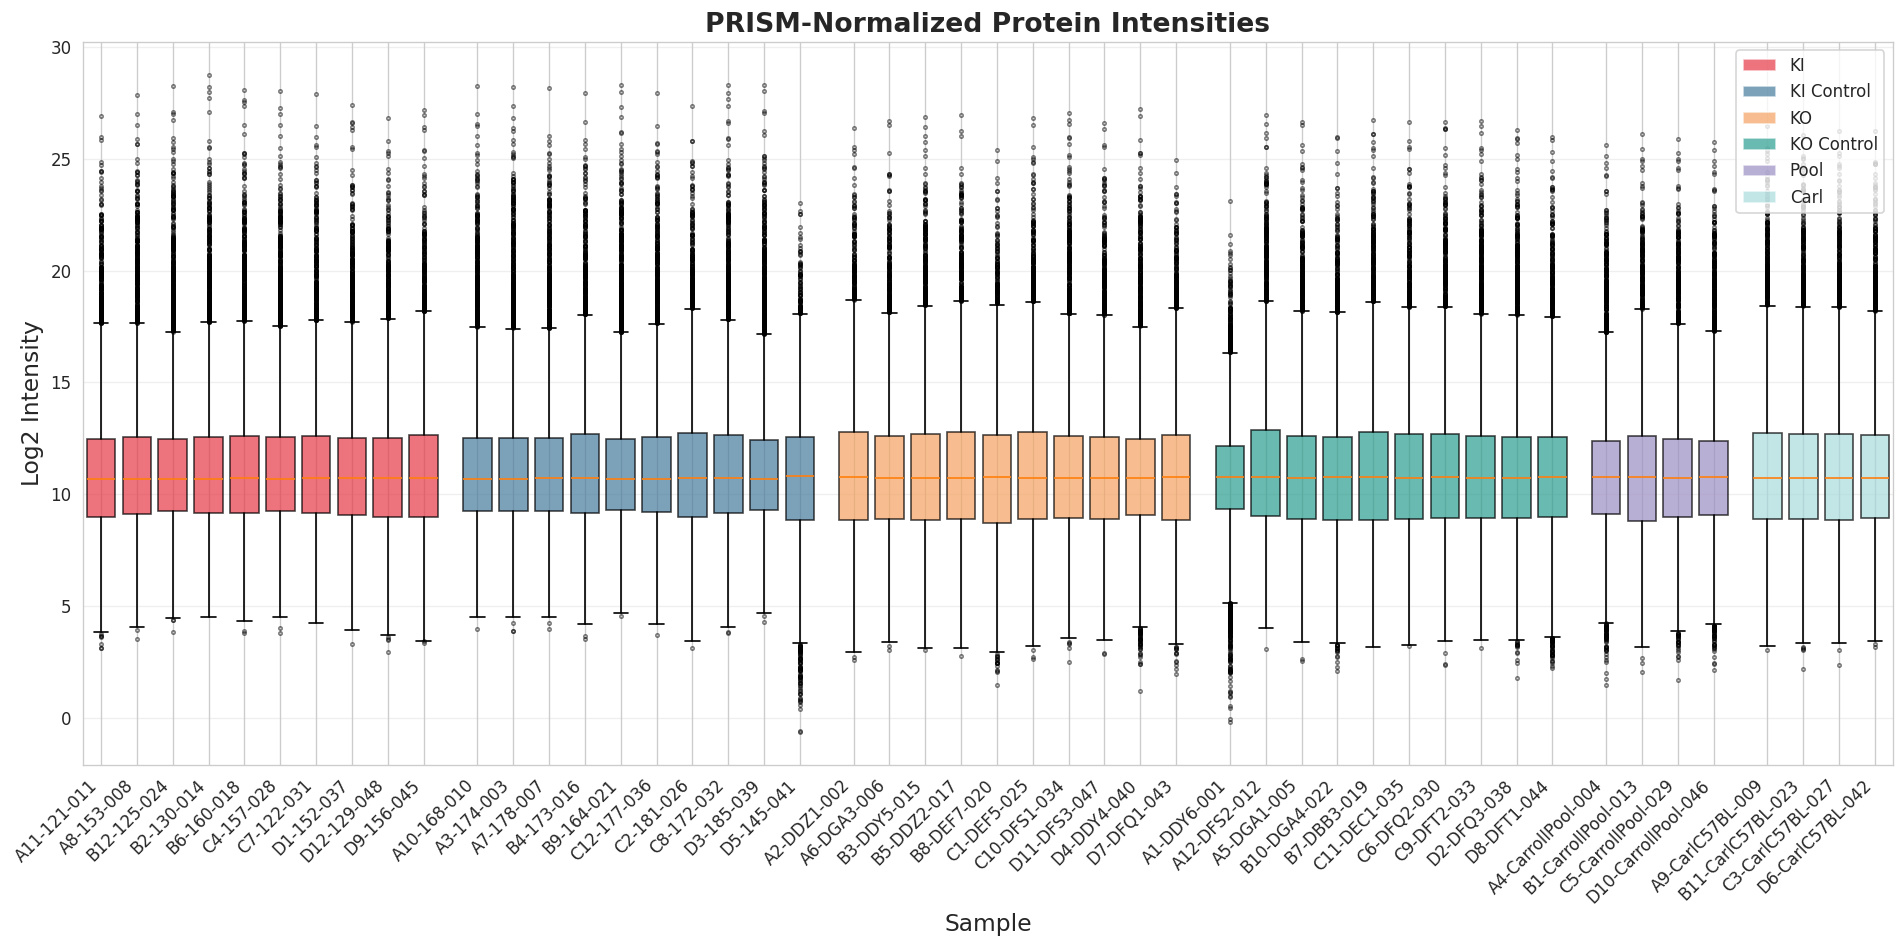

Box plot summary:
Total samples plotted: 48
Average proteins per sample: 8142


<Figure size 768x576 with 0 Axes>

In [6]:
os.makedirs('figures', exist_ok=True)

# Box plot of PRISM-normalized protein intensities
ptk.plot_box_plot(
    data=protein_data_filtered,
    sample_columns=sample_columns,
    sample_metadata=meta_dict,
    group_colors=GROUP_COLORS,
    group_order=GROUP_ORDER,
    log_transform=True,
    title='PRISM-Normalized Protein Intensities'
)
plt.tight_layout()
plt.savefig('figures/01_protein_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

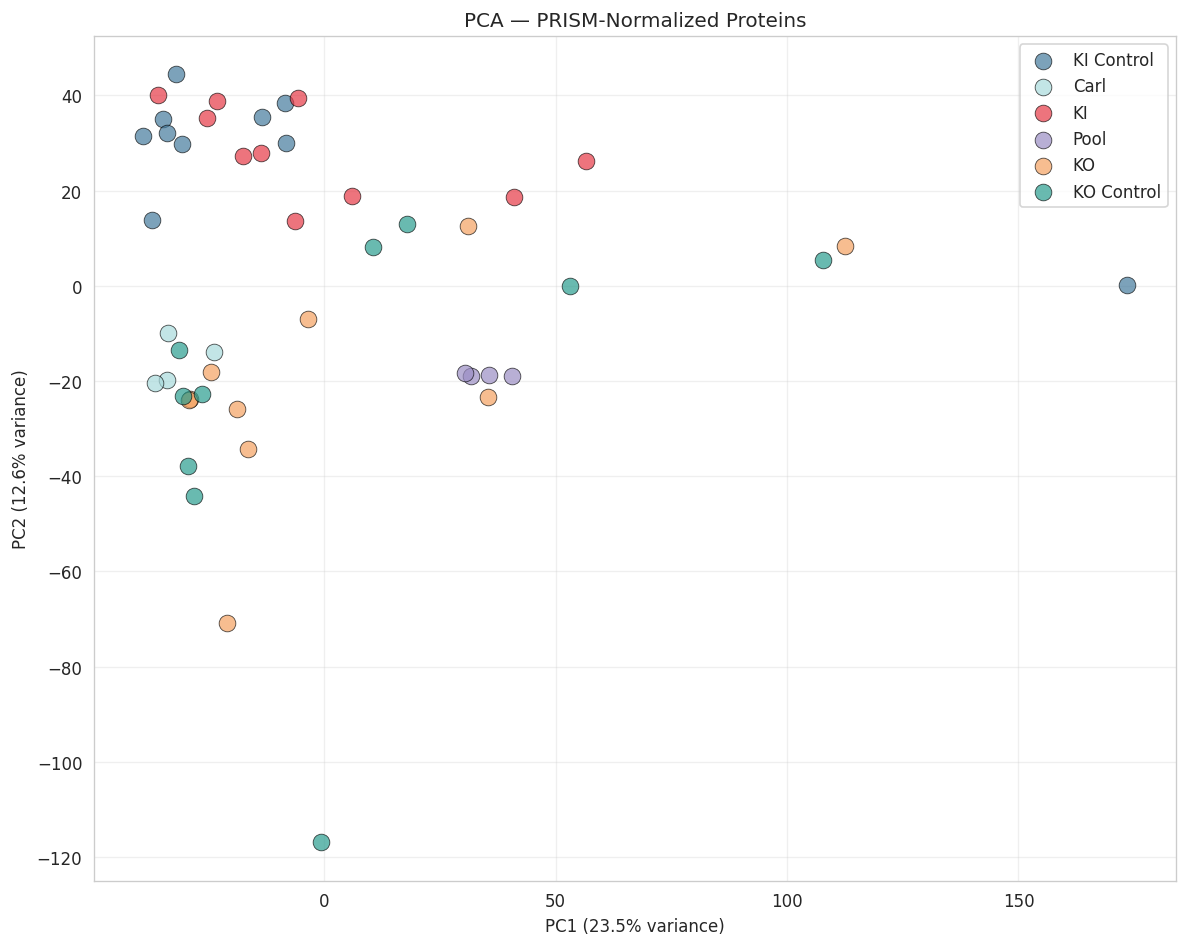

PCA summary:
PC1 explains 23.5% of variance
PC2 explains 12.6% of variance
Total variance explained: 36.1%


<Figure size 768x576 with 0 Axes>

In [7]:
# PCA — PRISM-normalized proteins
ptk.plot_pca(
    data=protein_data_filtered,
    sample_columns=sample_columns,
    sample_metadata=meta_dict,
    group_colors=GROUP_COLORS,
    title='PCA — PRISM-Normalized Proteins',
    log_transform=True,
)
plt.tight_layout()
plt.savefig('figures/02_pca.png', dpi=150, bbox_inches='tight')
plt.show()

Pool samples: 4
Carl samples: 4
Mean r = 0.892, Min r = 0.781, Max r = 0.998


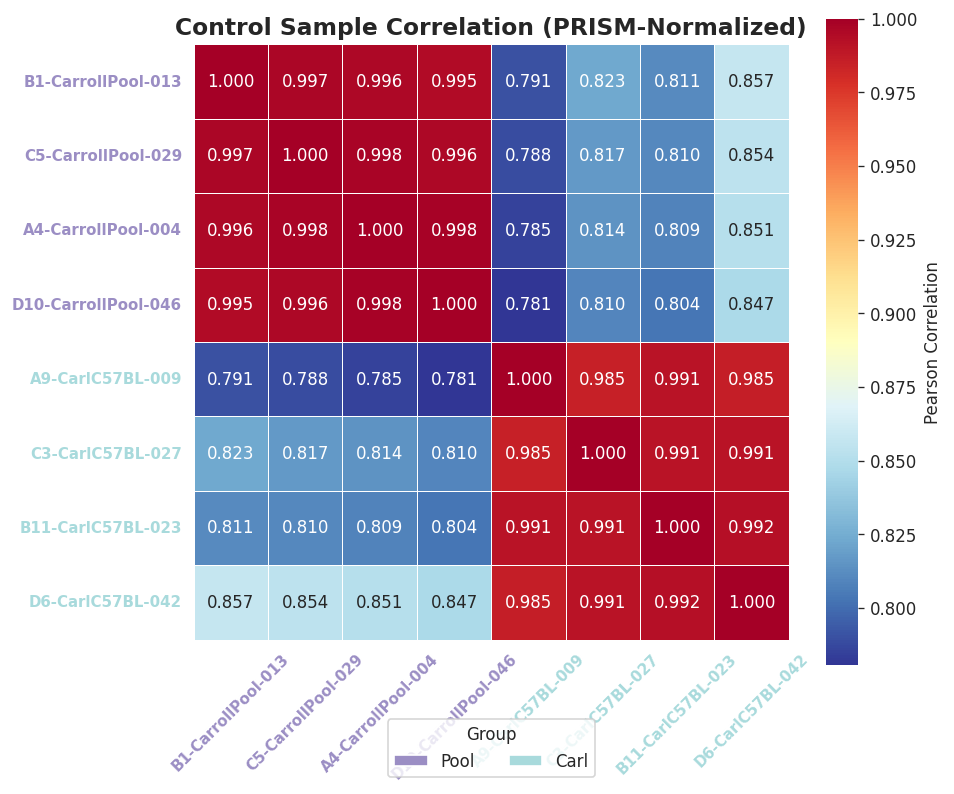

In [8]:
# Control sample correlation — Pool + Carl combined, clustered
pool_cols = [col for col in sample_columns if meta_dict.get(col, {}).get('Group') == 'Pool']
carl_cols = [col for col in sample_columns if meta_dict.get(col, {}).get('Group') == 'Carl']
control_cols = pool_cols + carl_cols

print(f"Pool samples: {len(pool_cols)}")
print(f"Carl samples: {len(carl_cols)}")

ptk.plot_control_correlation(
    data=protein_data_filtered,
    control_columns=control_cols,
    sample_metadata=meta_dict,
    title='Control Sample Correlation (PRISM-Normalized)',
    cluster=True,
    group_colors=GROUP_COLORS,
)
plt.savefig('figures/03_control_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 3. Statistical Analysis

Differential protein abundance analysis between experimental groups using the PRISM-normalized values.

PRISM data is already log2-like (the output of median-polish rollup is on a log scale internally). The toolkit's `StatisticalConfig` handles this via `normalization_method='prism'`.

**Contrasts:**
1. KI vs KI Control (Huntington's KI effect at 12 weeks)
2. KO vs KO Control (conditional KO effect at 7 weeks)
3. KO Control vs KI Control (baseline age/strain difference between controls)
4. Male vs Female (sex effect across all experimental samples)

In [9]:
# Restrict to experimental samples only (exclude Pool and Carl)
STUDY_GROUPS = ['KI', 'KI Control', 'KO', 'KO Control']

study_cols = [
    col for col in sample_columns
    if meta_dict.get(col, {}).get('Group') in STUDY_GROUPS
]
print(f"Study sample columns: {len(study_cols)}")

# Build a simplified metadata for stats (Replicate + Group columns)
sample_meta_df = pd.DataFrame([
    {
        'Replicate': col,
        'Group': meta_dict[col].get('Group', 'Unknown'),
        'Sex': meta_dict[col].get('Sex', ''),
        'Age': meta_dict[col].get('Age', ''),
        'Genotype': meta_dict[col].get('Genotype', ''),
    }
    for col in study_cols
])
print(sample_meta_df['Group'].value_counts().to_string())

Study sample columns: 40
Group
KO Control    10
KI Control    10
KI            10
KO            10


In [10]:
# ── KI vs KI Control ──────────────────────────────────────────────────────────

ki_config = ptk.StatisticalConfig()
ki_config.analysis_type = 'unpaired'
ki_config.group_column = 'Group'
ki_config.group_labels = ['KI Control', 'KI']  # [reference, study] → logFC = KI - KI Control
ki_config.statistical_test_method = 'welch_t'
ki_config.correction_method = 'fdr_bh'
ki_config.p_value_threshold = 0.05
ki_config.log_transform_before_stats = True
ki_config.normalization_method = 'prism'

# Build sample metadata dict for KI samples
ki_cols = [
    col for col in study_cols
    if meta_dict[col].get('Group') in ['KI', 'KI Control']
]
ki_meta = {col: meta_dict[col] for col in ki_cols}

# Build data with 5 standard annotation columns + sample columns for stats
ki_annot = protein_data_filtered[['leading_protein', 'leading_description', 'leading_gene_name', 'leading_uniprot_id', 'leading_name']].copy()
ki_annot.columns = ['Protein', 'Description', 'Protein Gene', 'UniProt_Accession', 'UniProt_Entry_Name']
ki_data = pd.concat([ki_annot.reset_index(drop=True), protein_data_filtered[ki_cols].reset_index(drop=True)], axis=1)

ki_results = ptk.run_comprehensive_statistical_analysis(
    ki_data, ki_meta, ki_config, protein_annotations=ki_annot
)

ptk.display_analysis_summary(ki_results, ki_config)
print(f"\nResult columns: {list(ki_results.columns)}")
ki_results.head()

STATISTICAL ANALYSIS
Log transformation: ENABLED (forced by configuration)
Applying log2 transformation for statistical analysis...
  -> Applied log2 transformation with pseudocount 0.006483743971352266
  -> New data range: -0.61 to 28.75
  -> New mean: 11.12
Step 1: Cleaning and validating sample metadata...
  Using standardized data structure: 20 sample columns (columns 6+)
  Sample columns: ['A10-168-010__@__2025-5-Carroll-Mouse-EV-PRISM', 'A11-121-011__@__2025-5-Carroll-Mouse-EV-PRISM', 'A3-174-003__@__2025-5-Carroll-Mouse-EV-PRISM']...
Preparing metadata for 20 samples...
  Before filtering: 20 samples
  After filtering: 20 samples
  Groups: {'KI Control': 10, 'KI': 10}
  Group variable treatment: CONTINUOUS (type: str)

Step 2: Analyzing experimental design...
  Valid experimental samples: 20

Step 3: Running welch_t analysis...
  Method: welch_t
  Analysis type: unpaired
  Proteins: 8142
  Samples: 20
  Groups: ['KI Control', 'KI']
Running unpaired t-test analysis...
  Processed

,Protein,logFC,AveExpr,t,P.Value,B,n_group1,n_group2,cohens_d,test_method,adj.P.Val,Significant,Significance,Description,Protein Gene,UniProt_Accession,UniProt_Entry_Name,Gene
7880,Q9WTU6,-0.616445,10.065677,-5.043315,0.000114,NaN,10,10,-2.255439,Welch's t-test,0.927404,False,Not significant,Mitogen-activated protein kinase 9,Mapk9,Q9WTU6,Mapk9,Mapk9
1851,P42859,-0.694178,11.846741,-4.252330,0.000479,NaN,10,10,-1.901700,Welch's t-test,0.999960,False,Not significant,Huntingtin,Htt,P42859,Htt,Htt
5763,Q8VE18,-0.636126,10.266386,-4.355616,0.000550,NaN,10,10,-1.947891,Welch's t-test,0.999960,False,Not significant,Nonsense-mediated mRNA decay factor SMG8,Smg8,Q8VE18,Smg8,Smg8
1020,O88712,-0.521736,11.274137,-4.270019,0.000577,NaN,10,10,-1.909611,Welch's t-test,0.999960,False,Not significant,C-terminal-binding protein 1,Ctbp1,O88712,Ctbp1,Ctbp1
7124,Q9DB90,-0.663611,10.046378,-3.940474,0.000968,NaN,10,10,-1.762233,Welch's t-test,0.999960,False,Not significant,Nonsense-mediated mRNA decay factor SMG9,Smg9,Q9DB90,Smg9,Smg9


In [11]:
# ── KO vs KO Control ──────────────────────────────────────────────────────────

ko_config = ptk.StatisticalConfig()
ko_config.analysis_type = 'unpaired'
ko_config.group_column = 'Group'
ko_config.group_labels = ['KO Control', 'KO']  # [reference, study] → logFC = KO - KO Control
ko_config.statistical_test_method = 'welch_t'
ko_config.correction_method = 'fdr_bh'
ko_config.p_value_threshold = 0.05
ko_config.log_transform_before_stats = True
ko_config.normalization_method = 'prism'

# Build sample metadata dict for KO samples
ko_cols = [
    col for col in study_cols
    if meta_dict[col].get('Group') in ['KO', 'KO Control']
]
ko_meta = {col: meta_dict[col] for col in ko_cols}

# Build data with 5 standard annotation columns + sample columns for stats
ko_annot = protein_data_filtered[['leading_protein', 'leading_description', 'leading_gene_name', 'leading_uniprot_id', 'leading_name']].copy()
ko_annot.columns = ['Protein', 'Description', 'Protein Gene', 'UniProt_Accession', 'UniProt_Entry_Name']
ko_data = pd.concat([ko_annot.reset_index(drop=True), protein_data_filtered[ko_cols].reset_index(drop=True)], axis=1)

ko_results = ptk.run_comprehensive_statistical_analysis(
    ko_data, ko_meta, ko_config, protein_annotations=ko_annot
)

ptk.display_analysis_summary(ko_results, ko_config)
print(f"\nResult columns: {list(ko_results.columns)}")
ko_results.head()

STATISTICAL ANALYSIS
Log transformation: ENABLED (forced by configuration)
Applying log2 transformation for statistical analysis...
  -> Applied log2 transformation with pseudocount 0.008764010870783242
  -> New data range: -0.18 to 27.24
  -> New mean: 10.96
Step 1: Cleaning and validating sample metadata...
  Using standardized data structure: 20 sample columns (columns 6+)
  Sample columns: ['A1-DDY6-001__@__2025-5-Carroll-Mouse-EV-PRISM', 'A12-DFS2-012__@__2025-5-Carroll-Mouse-EV-PRISM', 'A2-DDZ1-002__@__2025-5-Carroll-Mouse-EV-PRISM']...
Preparing metadata for 20 samples...
  Before filtering: 20 samples
  After filtering: 20 samples
  Groups: {'KO Control': 10, 'KO': 10}
  Group variable treatment: CONTINUOUS (type: str)

Step 2: Analyzing experimental design...
  Valid experimental samples: 20

Step 3: Running welch_t analysis...
  Method: welch_t
  Analysis type: unpaired
  Proteins: 8142
  Samples: 20
  Groups: ['KO Control', 'KO']
Running unpaired t-test analysis...
  Process

,Protein,logFC,AveExpr,t,P.Value,B,n_group1,n_group2,cohens_d,test_method,adj.P.Val,Significant,Significance,Description,Protein Gene,UniProt_Accession,UniProt_Entry_Name,Gene
1851,P42859,-2.355083,10.976646,-10.708645,4.895141e-09,NaN,10,10,-4.789051,Welch's t-test,0.000040,True,Highly significant (FDR < 0.01),Huntingtin,Htt,P42859,Htt,Htt
1653,P28293,4.324787,14.383631,8.458729,3.611245e-07,NaN,10,10,3.782858,Welch's t-test,0.001470,True,Highly significant (FDR < 0.01),Cathepsin G,Ctsg,P28293,Ctsg,Ctsg
2633,Q00558,-3.042183,12.033085,-8.688992,7.984255e-07,NaN,10,10,-3.885835,Welch's t-test,0.002167,True,Highly significant (FDR < 0.01),40-kDa huntingtin-associated protein,F8a1,Q00558,F8a1,F8a1
3420,Q61096,3.965097,11.534454,7.597921,1.746188e-06,NaN,10,10,3.397893,Welch's t-test,0.002951,True,Highly significant (FDR < 0.01),Myeloblastin,Prtn3,Q61096,Prtn3,Prtn3
5716,Q8VCX6,-2.944341,9.201037,-8.288149,1.812239e-06,NaN,10,10,-3.706573,Welch's t-test,0.002951,True,Highly significant (FDR < 0.01),KICSTOR complex protein kaptin,Kptn,Q8VCX6,Kptn,Kptn


In [12]:
# ── KO Control vs KI Control ───────────────────────────────────────────────────

ctrl_config = ptk.StatisticalConfig()
ctrl_config.analysis_type = 'unpaired'
ctrl_config.group_column = 'Group'
ctrl_config.group_labels = ['KI Control', 'KO Control']  # [reference, study] → logFC = KO Control - KI Control
ctrl_config.statistical_test_method = 'welch_t'
ctrl_config.correction_method = 'fdr_bh'
ctrl_config.p_value_threshold = 0.05
ctrl_config.log_transform_before_stats = True
ctrl_config.normalization_method = 'prism'

# Build sample metadata dict for control samples
ctrl_cols = [
    col for col in study_cols
    if meta_dict[col].get('Group') in ['KI Control', 'KO Control']
]
ctrl_meta = {col: meta_dict[col] for col in ctrl_cols}

# Build data with 5 standard annotation columns + sample columns
ctrl_annot = protein_data_filtered[['leading_protein', 'leading_description', 'leading_gene_name', 'leading_uniprot_id', 'leading_name']].copy()
ctrl_annot.columns = ['Protein', 'Description', 'Protein Gene', 'UniProt_Accession', 'UniProt_Entry_Name']
ctrl_data = pd.concat([ctrl_annot.reset_index(drop=True), protein_data_filtered[ctrl_cols].reset_index(drop=True)], axis=1)

ctrl_results = ptk.run_comprehensive_statistical_analysis(
    ctrl_data, ctrl_meta, ctrl_config, protein_annotations=ctrl_annot
)

ptk.display_analysis_summary(ctrl_results, ctrl_config)
ctrl_results.head()

STATISTICAL ANALYSIS
Log transformation: ENABLED (forced by configuration)
Applying log2 transformation for statistical analysis...
  -> Applied log2 transformation with pseudocount 0.006483743971352266
  -> New data range: -0.61 to 28.30
  -> New mean: 11.05
Step 1: Cleaning and validating sample metadata...
  Using standardized data structure: 20 sample columns (columns 6+)
  Sample columns: ['A1-DDY6-001__@__2025-5-Carroll-Mouse-EV-PRISM', 'A10-168-010__@__2025-5-Carroll-Mouse-EV-PRISM', 'A12-DFS2-012__@__2025-5-Carroll-Mouse-EV-PRISM']...
Preparing metadata for 20 samples...
  Before filtering: 20 samples
  After filtering: 20 samples
  Groups: {'KO Control': 10, 'KI Control': 10}
  Group variable treatment: CONTINUOUS (type: str)

Step 2: Analyzing experimental design...
  Valid experimental samples: 20

Step 3: Running welch_t analysis...
  Method: welch_t
  Analysis type: unpaired
  Proteins: 8142
  Samples: 20
  Groups: ['KI Control', 'KO Control']
Running unpaired t-test analy

,Protein,logFC,AveExpr,t,P.Value,B,n_group1,n_group2,cohens_d,test_method,adj.P.Val,Significant,Significance,Description,Protein Gene,UniProt_Accession,UniProt_Entry_Name,Gene
2738,Q07076,0.963788,14.056067,11.126248,3.148593e-09,NaN,10,10,4.975809,Welch's t-test,0.000026,True,Highly significant (FDR < 0.01),Annexin A7,Anxa7,Q07076,Anxa7,Anxa7
2741,Q07235,3.351341,16.591897,8.858656,9.351728e-08,NaN,10,10,3.961712,Welch's t-test,0.000381,True,Highly significant (FDR < 0.01),Glia-derived nexin,Serpine2,Q07235,Serpine2,Serpine2
1456,P17182,1.715891,14.713554,8.667133,1.531846e-07,NaN,10,10,3.876060,Welch's t-test,0.000392,True,Highly significant (FDR < 0.01),Alpha-enolase,Eno1,P17182,Eno1,Eno1
2302,P62702,1.538051,14.043829,8.051611,2.287363e-07,NaN,10,10,3.600790,Welch's t-test,0.000392,True,Highly significant (FDR < 0.01),Small ribosomal subunit protein eS4,Rps4x,P62702,Rps4x,Rps4x
6370,Q99LX0,2.016959,13.461719,8.032178,2.405627e-07,NaN,10,10,3.592099,Welch's t-test,0.000392,True,Highly significant (FDR < 0.01),Parkinson disease protein 7 homolog,Park7,Q99LX0,Park7,Park7


In [13]:
# ── Male vs Female (all experimental samples) ─────────────────────────────────

sex_config = ptk.StatisticalConfig()
sex_config.analysis_type = 'unpaired'
sex_config.group_column = 'Sex'
sex_config.group_labels = ['F', 'M']  # [reference, study] → logFC = Male - Female
sex_config.statistical_test_method = 'welch_t'
sex_config.correction_method = 'fdr_bh'
sex_config.p_value_threshold = 0.05
sex_config.log_transform_before_stats = True
sex_config.normalization_method = 'prism'

# Build sample metadata dict for all experimental samples with Sex annotation
sex_cols = [
    col for col in study_cols
    if meta_dict[col].get('Sex') in ['M', 'F']
]
sex_meta = {col: meta_dict[col] for col in sex_cols}

print(f"Samples with sex annotation: {len(sex_cols)}")
from collections import Counter
sex_counts = Counter(meta_dict[col].get('Sex') for col in sex_cols)
for s, n in sorted(sex_counts.items()):
    print(f"  {s}: {n}")

# Build data with 5 standard annotation columns + sample columns
sex_annot = protein_data_filtered[['leading_protein', 'leading_description', 'leading_gene_name', 'leading_uniprot_id', 'leading_name']].copy()
sex_annot.columns = ['Protein', 'Description', 'Protein Gene', 'UniProt_Accession', 'UniProt_Entry_Name']
sex_data = pd.concat([sex_annot.reset_index(drop=True), protein_data_filtered[sex_cols].reset_index(drop=True)], axis=1)

sex_results = ptk.run_comprehensive_statistical_analysis(
    sex_data, sex_meta, sex_config, protein_annotations=sex_annot
)

ptk.display_analysis_summary(sex_results, sex_config)
sex_results.head()

Samples with sex annotation: 40
  F: 20
  M: 20
STATISTICAL ANALYSIS
Log transformation: ENABLED (forced by configuration)
Applying log2 transformation for statistical analysis...
  -> Applied log2 transformation with pseudocount 0.006483743971352266
  -> New data range: -0.61 to 28.75
  -> New mean: 11.04
Step 1: Cleaning and validating sample metadata...
  Using standardized data structure: 40 sample columns (columns 6+)
  Sample columns: ['A1-DDY6-001__@__2025-5-Carroll-Mouse-EV-PRISM', 'A10-168-010__@__2025-5-Carroll-Mouse-EV-PRISM', 'A11-121-011__@__2025-5-Carroll-Mouse-EV-PRISM']...
Preparing metadata for 40 samples...
  Before filtering: 40 samples
  After filtering: 40 samples
  Groups: {'F': 20, 'M': 20}
  Group variable treatment: CONTINUOUS (type: str)

Step 2: Analyzing experimental design...
  Valid experimental samples: 40

Step 3: Running welch_t analysis...
  Method: welch_t
  Analysis type: unpaired
  Proteins: 8142
  Samples: 40
  Groups: ['F', 'M']
Running unpaired t

,Protein,logFC,AveExpr,t,P.Value,B,n_group1,n_group2,cohens_d,test_method,adj.P.Val,Significant,Significance,Description,Protein Gene,UniProt_Accession,UniProt_Entry_Name,Gene
3572,Q62010,-4.959211,11.794857,-14.533834,2.779791e-13,NaN,20,20,-4.596002,Welch's t-test,2.263306e-09,True,Highly significant (FDR < 0.01),Oviduct-specific glycoprotein,Ovgp1,Q62010,Ovgp1,Ovgp1
2803,Q19LI2,-7.677883,14.947361,-12.830971,1.448997e-12,NaN,20,20,-4.057509,Welch's t-test,5.898869e-09,True,Highly significant (FDR < 0.01),Alpha-1B-glycoprotein,A1bg,Q19LI2,A1bg,A1bg
3214,Q5FW60,4.536019,11.116265,10.031478,3.172332e-12,NaN,20,20,3.172232,Welch's t-test,8.609708e-09,True,Highly significant (FDR < 0.01),Major urinary protein 20,Mup20,Q5FW60,Mup20,Mup20
2903,Q3TUY3,4.973246,13.209703,10.850186,1.135335e-11,NaN,20,20,3.431130,Welch's t-test,1.996326e-08,True,Highly significant (FDR < 0.01),Spermine binding protein-like,Sbpl,Q3TUY3,Sbpl,Sbpl
1413,P15501,5.297535,12.330694,10.976153,1.225943e-11,NaN,20,20,3.470964,Welch's t-test,1.996326e-08,True,Highly significant (FDR < 0.01),Prostatic spermine-binding protein,Sbp,P15501,Sbp,Sbp


---
## 4. Volcano Plots

Note: Automatically falling back to unadjusted p-values for visualization
    Note: Results shown use raw p-values, interpret with caution

KI (Q111) vs KI Control
(PRISM-Normalized)


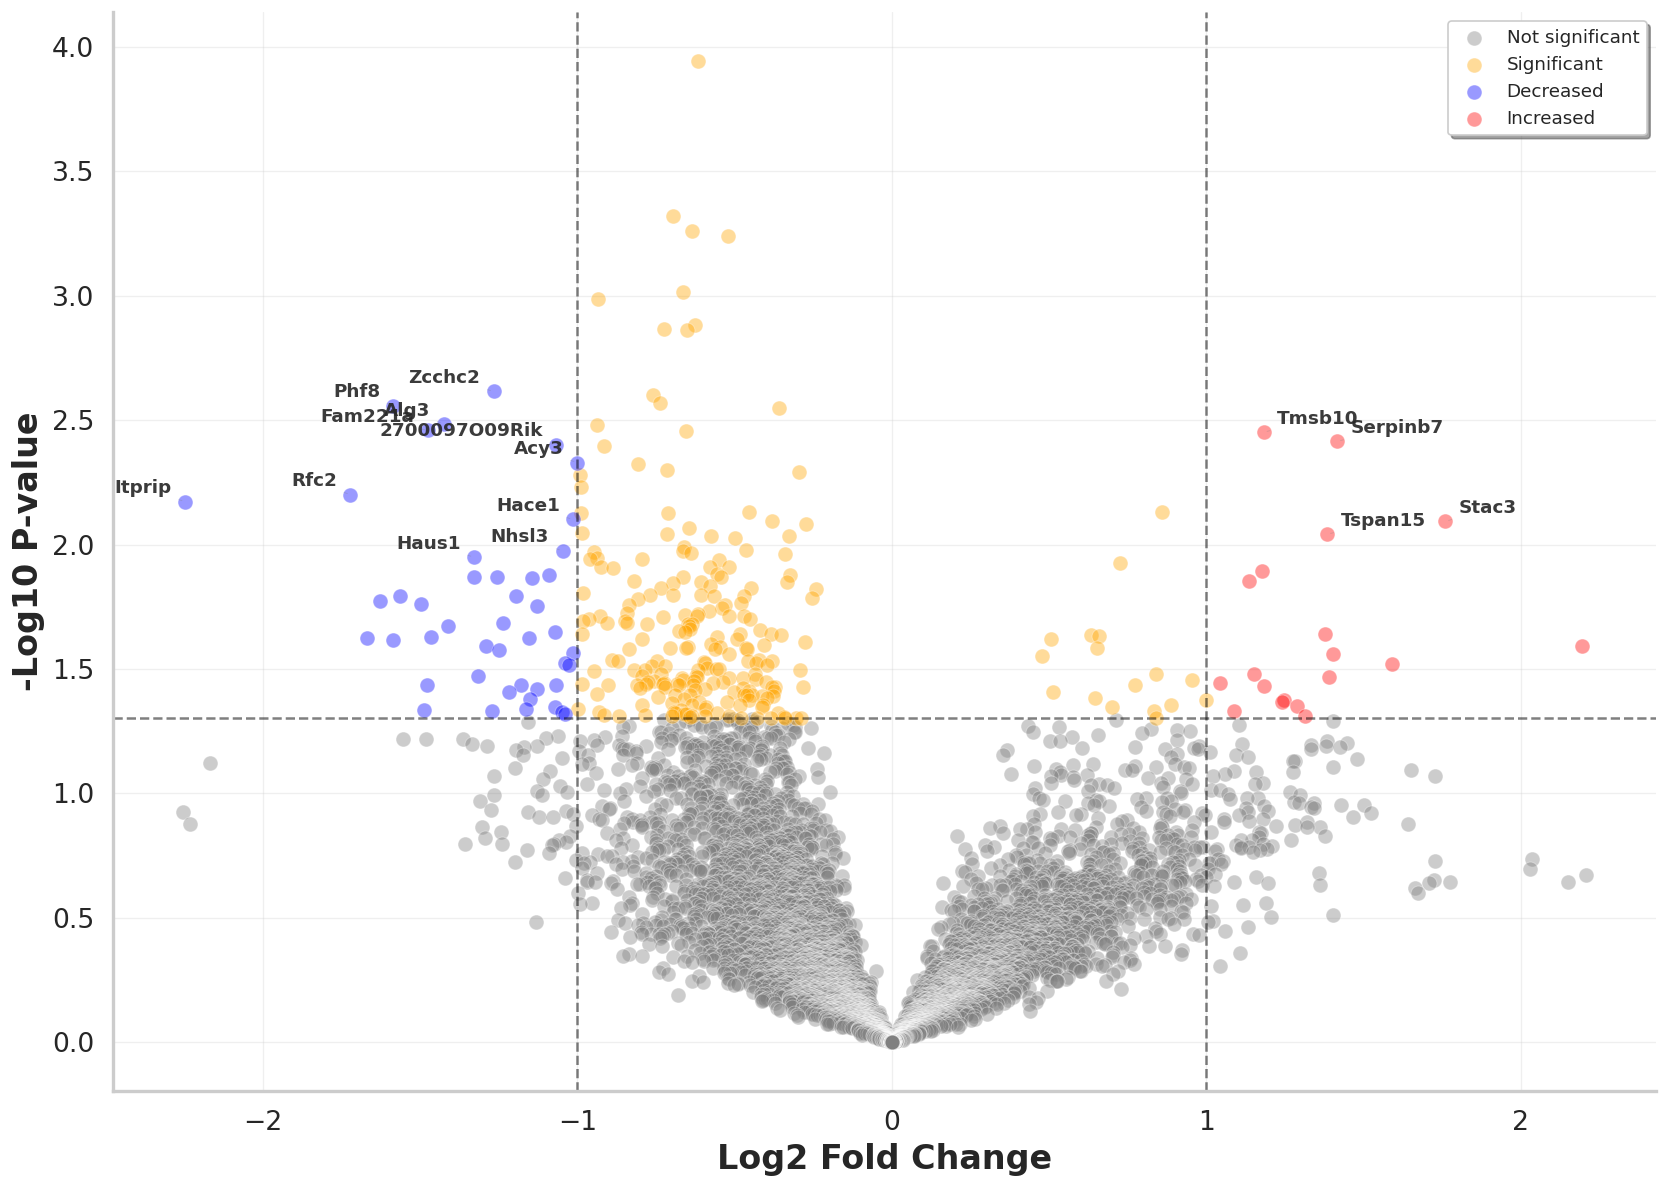

Volcano plot summary:
Total proteins: 8142
P-value type used: P-value (fallback from FDR)
Significant (P-value < 0.05): 294
Up-regulated (FC > 1.0, P-value < 0.05): 19
Down-regulated (FC < -1.0, P-value < 0.05): 45


<Figure size 768x576 with 0 Axes>

In [14]:
os.makedirs('figures', exist_ok=True)

# KI vs KI Control volcano
ptk.plot_volcano(
    ki_results,
    title='KI (Q111) vs KI Control\n(PRISM-Normalized)',
    fc_threshold=1.0,
    p_threshold=0.05,
    label_top_n=15,
    gene_column='Protein Gene',
    normalization_method='prism',
)
plt.savefig('figures/05_volcano_KI_vs_KIControl.png', dpi=150, bbox_inches='tight')
plt.show()


KO (fl/fl; CAG/+) vs KO Control
(PRISM-Normalized)


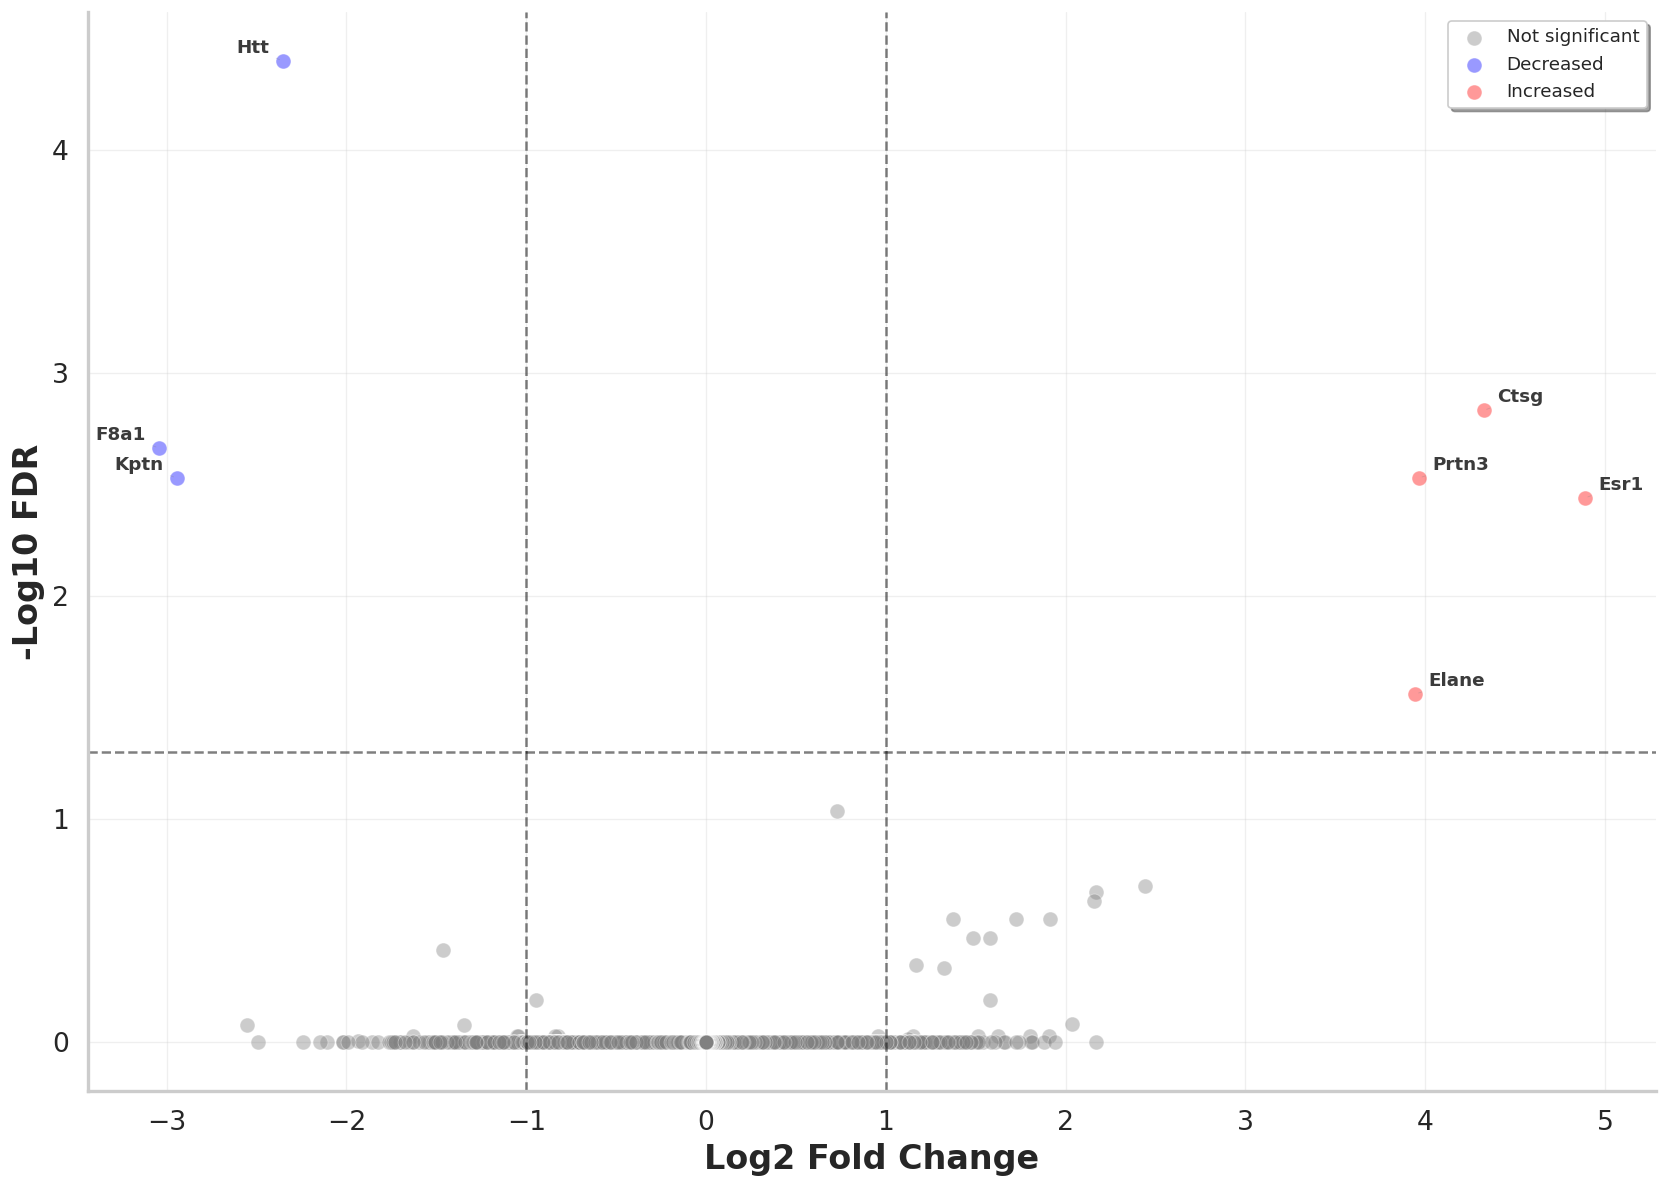

Volcano plot summary:
Total proteins: 8142
P-value type used: FDR (adjusted)
Significant (FDR < 0.05): 7
Up-regulated (FC > 1.0, FDR < 0.05): 4
Down-regulated (FC < -1.0, FDR < 0.05): 3


<Figure size 768x576 with 0 Axes>

In [15]:
# KO vs KO Control volcano
ptk.plot_volcano(
    ko_results,
    title='KO (fl/fl; CAG/+) vs KO Control\n(PRISM-Normalized)',
    fc_threshold=1.0,
    p_threshold=0.05,
    label_top_n=15,
    gene_column='Protein Gene',
    normalization_method='prism',
)
plt.savefig('figures/06_volcano_KO_vs_KOControl.png', dpi=150, bbox_inches='tight')
plt.show()


KO Control vs KI Control
(PRISM-Normalized)


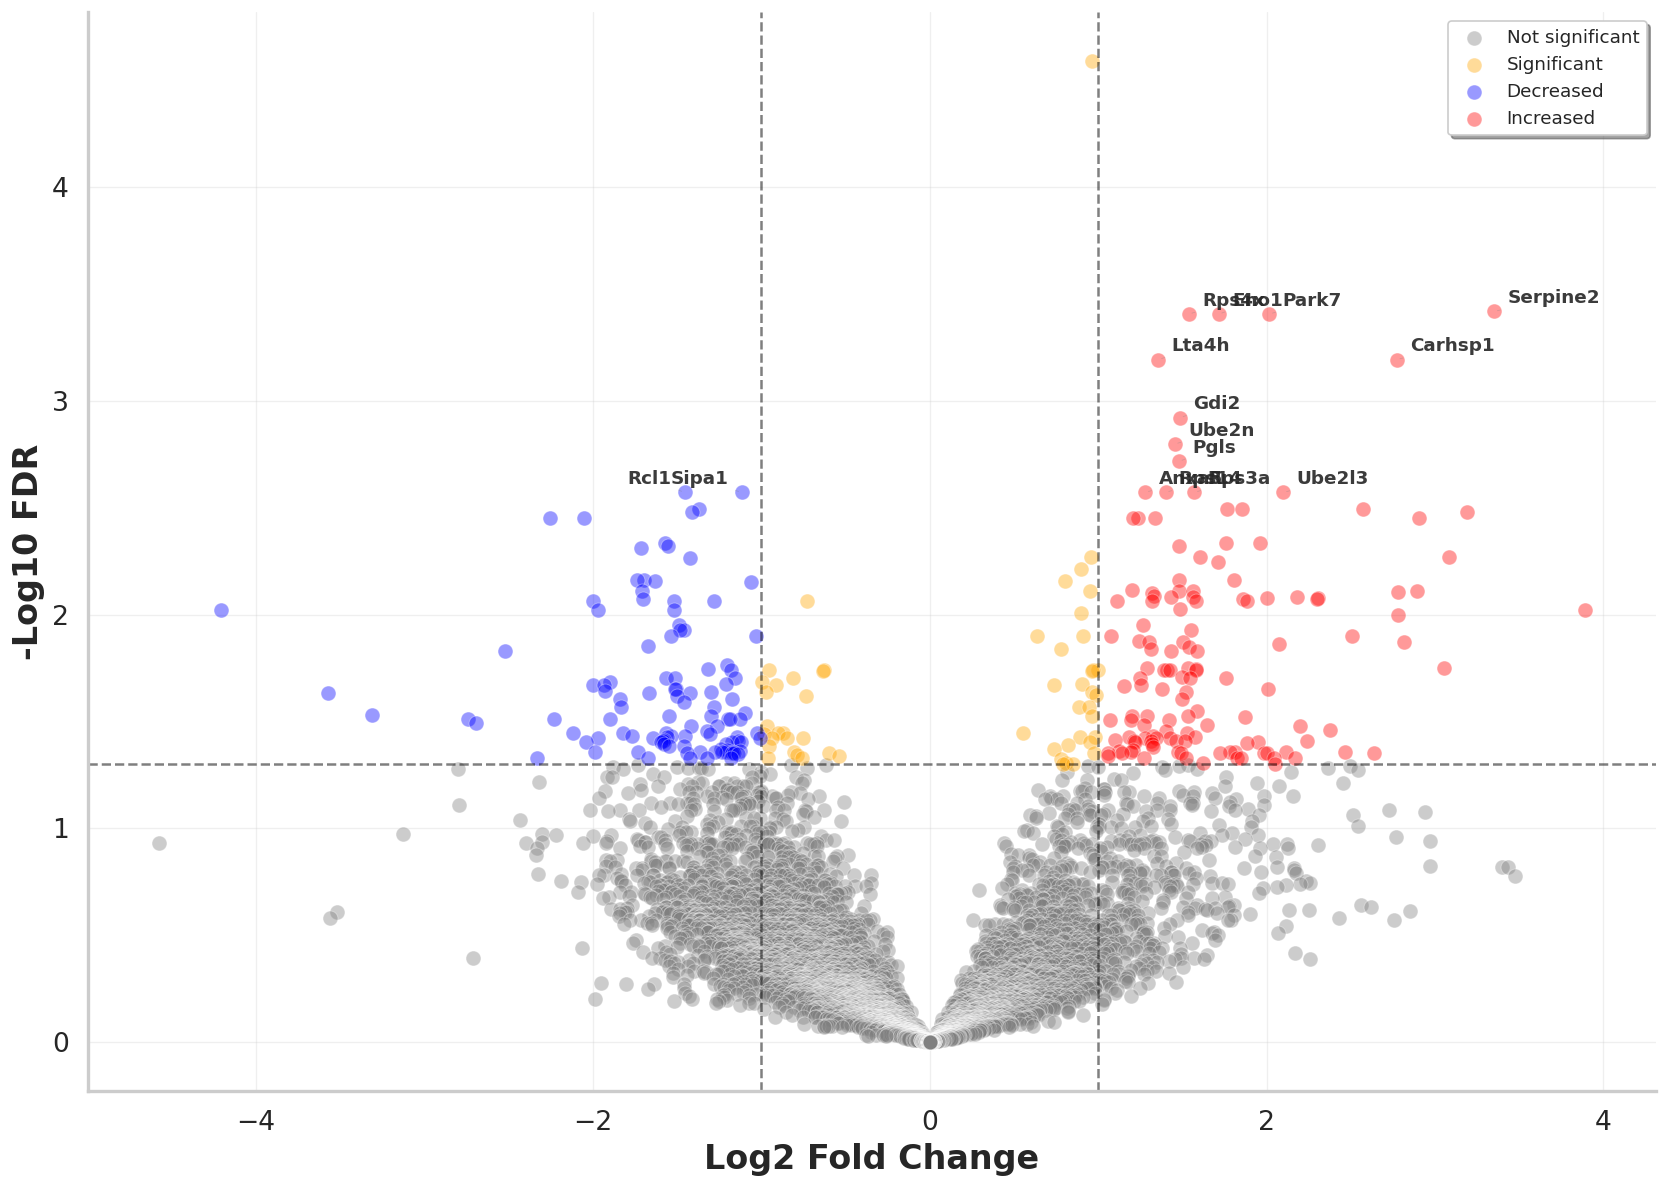

Volcano plot summary:
Total proteins: 8142
P-value type used: FDR (adjusted)
Significant (FDR < 0.05): 298
Up-regulated (FC > 1.0, FDR < 0.05): 136
Down-regulated (FC < -1.0, FDR < 0.05): 109


<Figure size 768x576 with 0 Axes>

In [16]:
# KO Control vs KI Control volcano
ptk.plot_volcano(
    ctrl_results,
    title='KO Control vs KI Control\n(PRISM-Normalized)',
    fc_threshold=1.0,
    p_threshold=0.05,
    label_top_n=15,
    gene_column='Protein Gene',
    normalization_method='prism',
)
plt.savefig('figures/05b_volcano_KOControl_vs_KIControl.png', dpi=150, bbox_inches='tight')
plt.show()


Male vs Female (all experimental)
(PRISM-Normalized)


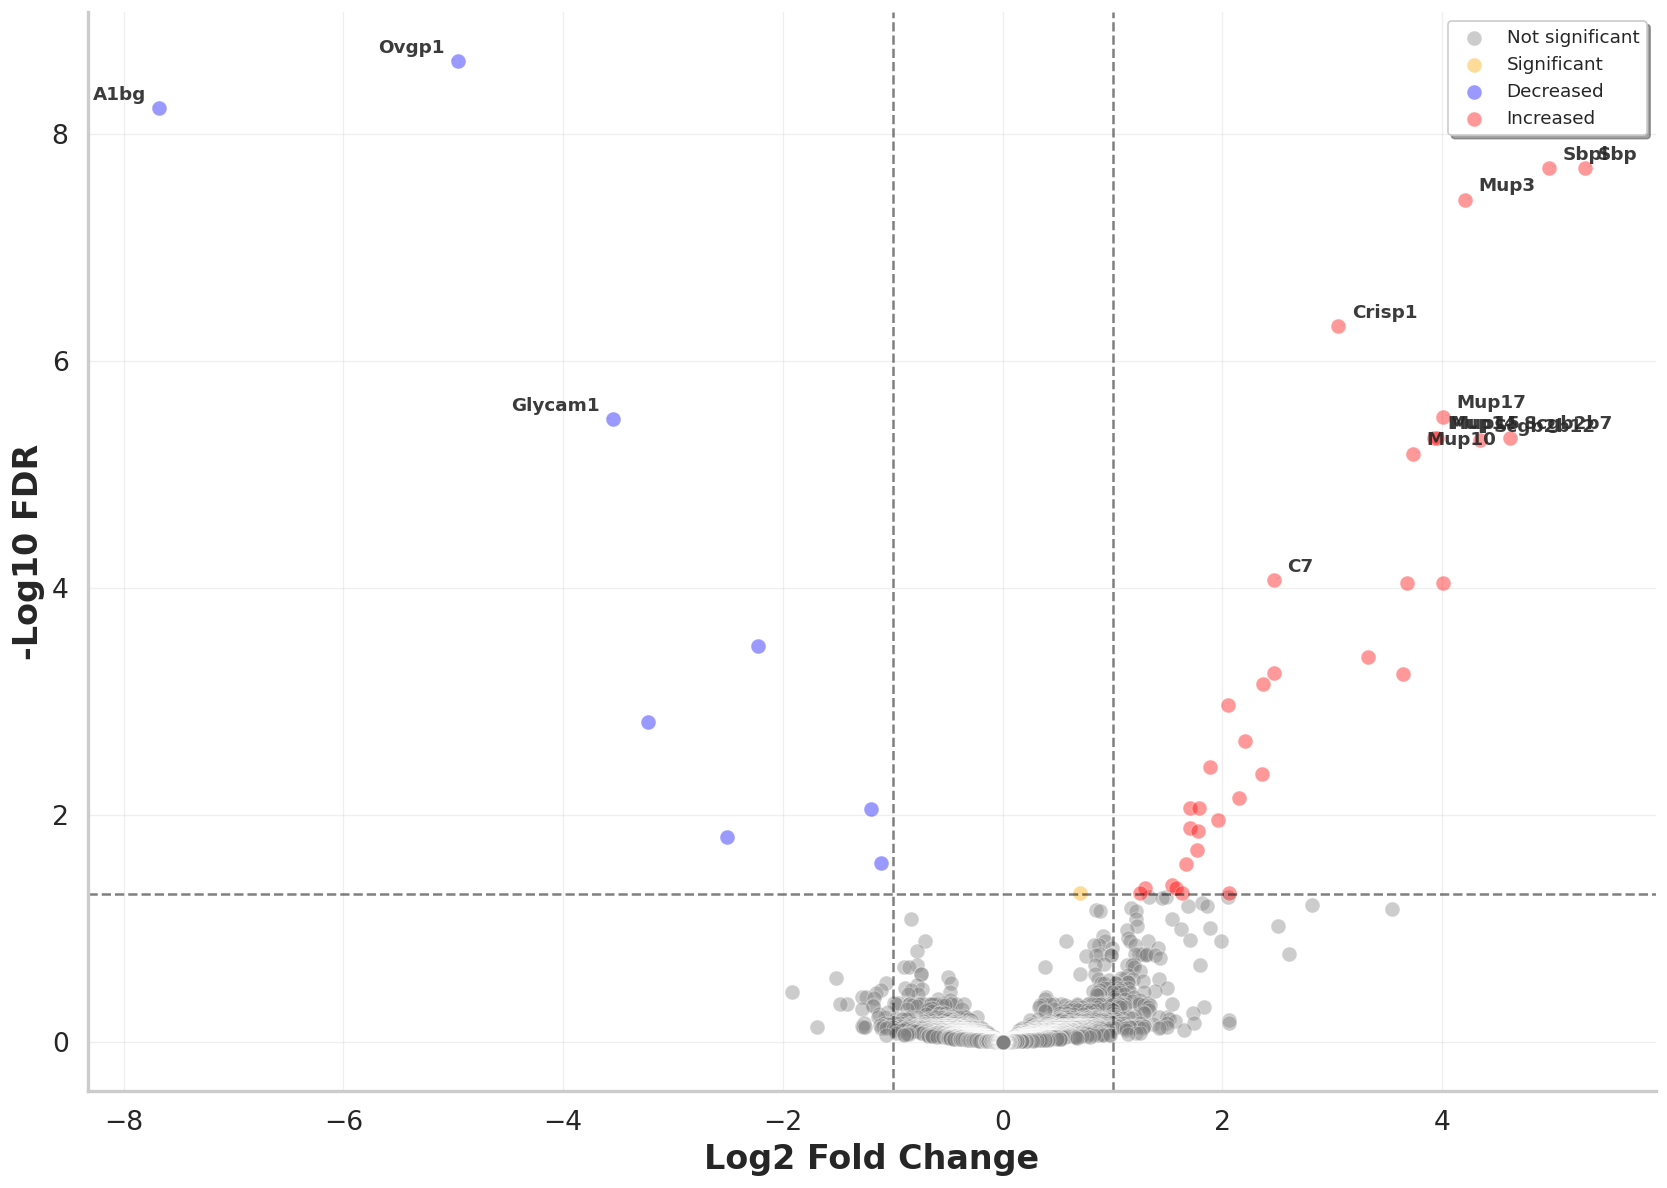

Volcano plot summary:
Total proteins: 8142
P-value type used: FDR (adjusted)
Significant (FDR < 0.05): 45
Up-regulated (FC > 1.0, FDR < 0.05): 36
Down-regulated (FC < -1.0, FDR < 0.05): 8


<Figure size 768x576 with 0 Axes>

In [17]:
# Male vs Female volcano
ptk.plot_volcano(
    sex_results,
    title='Male vs Female (all experimental)\n(PRISM-Normalized)',
    fc_threshold=1.0,
    p_threshold=0.05,
    label_top_n=15,
    gene_column='Protein Gene',
    normalization_method='prism',
)
plt.savefig('figures/05c_volcano_Male_vs_Female.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 5. Significant Protein Summary

In [18]:
def summarize_sig(results, label, fc_thresh=1.0, pval_thresh=0.05):
    """Quick summary of significant proteins."""
    df = results
    if df is None or df.empty:
        print(f"{label}: No results")
        return None

    pval_col = 'adj.P.Val'
    raw_pval_col = 'P.Value'
    fc_col = 'logFC'
    gene_col = 'Protein Gene'

    if pval_col not in df.columns or fc_col not in df.columns:
        print(f"{label}: Missing columns. Available: {list(df.columns)}")
        return df

    sig = df[(df[pval_col] < pval_thresh) & (df[fc_col].abs() >= fc_thresh)]
    up = sig[sig[fc_col] > 0]
    dn = sig[sig[fc_col] < 0]

    print(f"\n{'='*60}")
    print(f"{label}")
    print(f"  Total tested: {len(df)}")
    print(f"  Significant (|log2FC|≥{fc_thresh}, adj p<{pval_thresh}): {len(sig)}")
    print(f"    Up in study:    {len(up)}")
    print(f"    Down in study:  {len(dn)}")

    if gene_col in df.columns and len(sig) > 0:
        print(f"\n  Top significant (FDR-corrected):")
        top = sig.nsmallest(10, pval_col)
        for _, row in top.iterrows():
            g = row.get(gene_col, row.get('Protein', '?'))
            print(f"    {str(g):20s}  log2FC={row[fc_col]:+.2f}  adj.p={row[pval_col]:.2e}")

    # Top 20 by raw p-value regardless of multiple testing correction
    if gene_col in df.columns and raw_pval_col in df.columns:
        print(f"\n  Top 20 by raw p-value (uncorrected):")
        top20 = df.nsmallest(20, raw_pval_col)
        for _, row in top20.iterrows():
            g = row.get(gene_col, row.get('Protein', '?'))
            adj_p = row[pval_col]
            raw_p = row[raw_pval_col]
            fc = row[fc_col]
            marker = '*' if adj_p < pval_thresh and abs(fc) >= fc_thresh else ' '
            print(f"  {marker} {str(g):20s}  log2FC={fc:+.2f}  p={raw_p:.2e}  adj.p={adj_p:.2e}")

    return sig


ki_sig = summarize_sig(ki_results, 'KI vs KI Control')
ko_sig = summarize_sig(ko_results, 'KO vs KO Control')
ctrl_sig = summarize_sig(ctrl_results, 'KO Control vs KI Control')
sex_sig = summarize_sig(sex_results, 'Male vs Female (all experimental)')


KI vs KI Control
  Total tested: 8142
  Significant (|log2FC|≥1.0, adj p<0.05): 0
    Up in study:    0
    Down in study:  0

  Top 20 by raw p-value (uncorrected):
    Mapk9                 log2FC=-0.62  p=1.14e-04  adj.p=9.27e-01
    Htt                   log2FC=-0.69  p=4.79e-04  adj.p=1.00e+00
    Smg8                  log2FC=-0.64  p=5.50e-04  adj.p=1.00e+00
    Ctbp1                 log2FC=-0.52  p=5.77e-04  adj.p=1.00e+00
    Smg9                  log2FC=-0.66  p=9.68e-04  adj.p=1.00e+00
    Nudt2                 log2FC=-0.93  p=1.03e-03  adj.p=1.00e+00
    Sipa1                 log2FC=-0.63  p=1.31e-03  adj.p=1.00e+00
    Akap1                 log2FC=-0.72  p=1.36e-03  adj.p=1.00e+00
    Cryz                  log2FC=-0.65  p=1.37e-03  adj.p=1.00e+00
    Zcchc2                log2FC=-1.27  p=2.42e-03  adj.p=1.00e+00
    Sqstm1                log2FC=-0.76  p=2.50e-03  adj.p=1.00e+00
    Znf22                 log2FC=-0.74  p=2.69e-03  adj.p=1.00e+00
    Phf8                  log

---
## 6. Gene Set Enrichment Analysis

Using Enrichr API for gene set enrichment on differentially abundant proteins.

In [19]:
# Enrichment config
enrich_config = ptk.EnrichmentConfig(
    enrichr_libraries=['GO_Biological_Process_2023', 'GO_Molecular_Function_2023', 'KEGG_2021_Human'],
    pvalue_cutoff=0.05,
    top_n=20,
)

print("Enrichment config ready.")
print(f"Gene sets: {enrich_config.enrichr_libraries}")

Enrichment config ready.
Gene sets: ['GO_Biological_Process_2023', 'GO_Molecular_Function_2023', 'KEGG_2021_Human']


In [20]:
# ── KI enrichment ──────────────────────────────────────────────────────────────

if ki_results is not None and not ki_results.empty and 'Protein Gene' in ki_results.columns:
    ki_enrich_results = ptk.run_differential_enrichment(
        results_df=ki_results,
        gene_column='Protein Gene',
        logfc_column='logFC',
        pvalue_column='adj.P.Val',
        config=enrich_config,
    )

    if ki_enrich_results:
        for direction, enrich_df in ki_enrich_results.items():
            if not enrich_df.empty:
                print(f"\nKI {direction} enrichment — top results:")
                print(enrich_df[['Term', 'Adj_P_Value', 'N_Genes']].head(10).to_string(index=False))
                ptk.plot_enrichment_barplot(
                    enrich_df,
                    title=f'KI vs KI Control — {direction} proteins',
                    top_n=15,
                )
                plt.savefig(f'figures/07_enrichment_KI_{direction}.png', dpi=150, bbox_inches='tight')
                plt.show()
else:
    print("No gene name column found in KI results — skipping enrichment")

Significant genes: 0 up, 0 down

Upregulated (0 genes):
  Skipping - need at least 5 genes

Downregulated (0 genes):
  Skipping - need at least 5 genes


In [21]:
# ── KO enrichment ──────────────────────────────────────────────────────────────

if ko_results is not None and not ko_results.empty and 'Protein Gene' in ko_results.columns:
    ko_enrich_results = ptk.run_differential_enrichment(
        results_df=ko_results,
        gene_column='Protein Gene',
        logfc_column='logFC',
        pvalue_column='adj.P.Val',
        config=enrich_config,
    )

    if ko_enrich_results:
        for direction, enrich_df in ko_enrich_results.items():
            if not enrich_df.empty:
                print(f"\nKO {direction} enrichment — top results:")
                print(enrich_df[['Term', 'Adj_P_Value', 'N_Genes']].head(10).to_string(index=False))
                ptk.plot_enrichment_barplot(
                    enrich_df,
                    title=f'KO vs KO Control — {direction} proteins',
                    top_n=15,
                )
                plt.savefig(f'figures/08_enrichment_KO_{direction}.png', dpi=150, bbox_inches='tight')
                plt.show()
else:
    print("No gene name column found in KO results — skipping enrichment")

Significant genes: 4 up, 3 down

Upregulated (4 genes):
  Skipping - need at least 5 genes

Downregulated (3 genes):
  Skipping - need at least 5 genes


Significant genes: 136 up, 109 down

Upregulated (136 genes):
Running enrichment on 136 genes...
  Found 60 significant terms

Downregulated (109 genes):
Running enrichment on 109 genes...
  Found 52 significant terms

Control comparison Upregulated enrichment — top results:
                                                                 Term  Adj_P_Value  N_Genes
                                    Response To Lead Ion (GO:0010288) 4.215162e-04        3
Positive Regulation Of Protein K63-linked Ubiquitination (GO:1902523) 4.215162e-04        3
                                 Cytoplasmic Translation (GO:0002181) 6.737965e-11       13
                                                             Ribosome 3.067233e-11       15
                                      Glycolytic Process (GO:0006096) 1.739201e-04        5
                             Response To Steroid Hormone (GO:0048545) 1.739201e-04        5
                          Carbohydrate Catabolic Process (GO:0016052) 5.202261e-

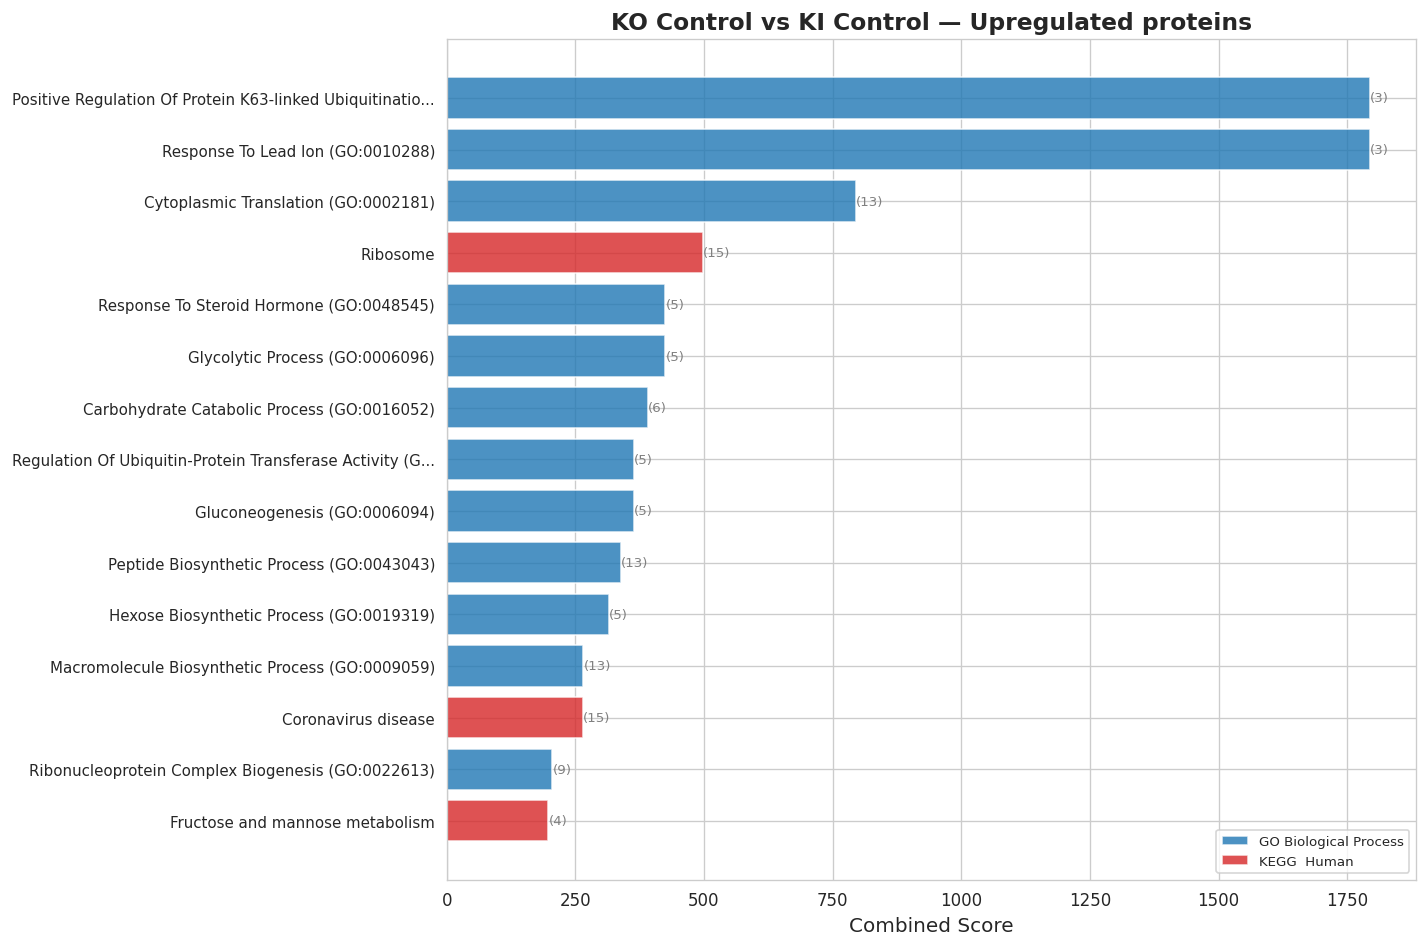


Control comparison Downregulated enrichment — top results:
                                                                Term  Adj_P_Value  N_Genes
                          Nuclear Pore Complex Assembly (GO:0051292)     0.003877        3
Oligosaccharide-Lipid Intermediate Biosynthetic Process (GO:0006490)     0.005289        3
                             Dolichol Metabolic Process (GO:0019348)     0.005788        3
                              Nuclear Pore Organization (GO:0006999)     0.005788        3
   Dolichol-Linked Oligosaccharide Biosynthetic Process (GO:0006488)     0.006177        3
                                      Nuclear Transport (GO:0051169)     0.001378        5
                                  Pore Complex Assembly (GO:0046931)     0.011329        3
                            Nucleocytoplasmic Transport (GO:0006913)     0.002418        5
                           Mannosyltransferase Activity (GO:0000030)     0.035544        3
                        Histon

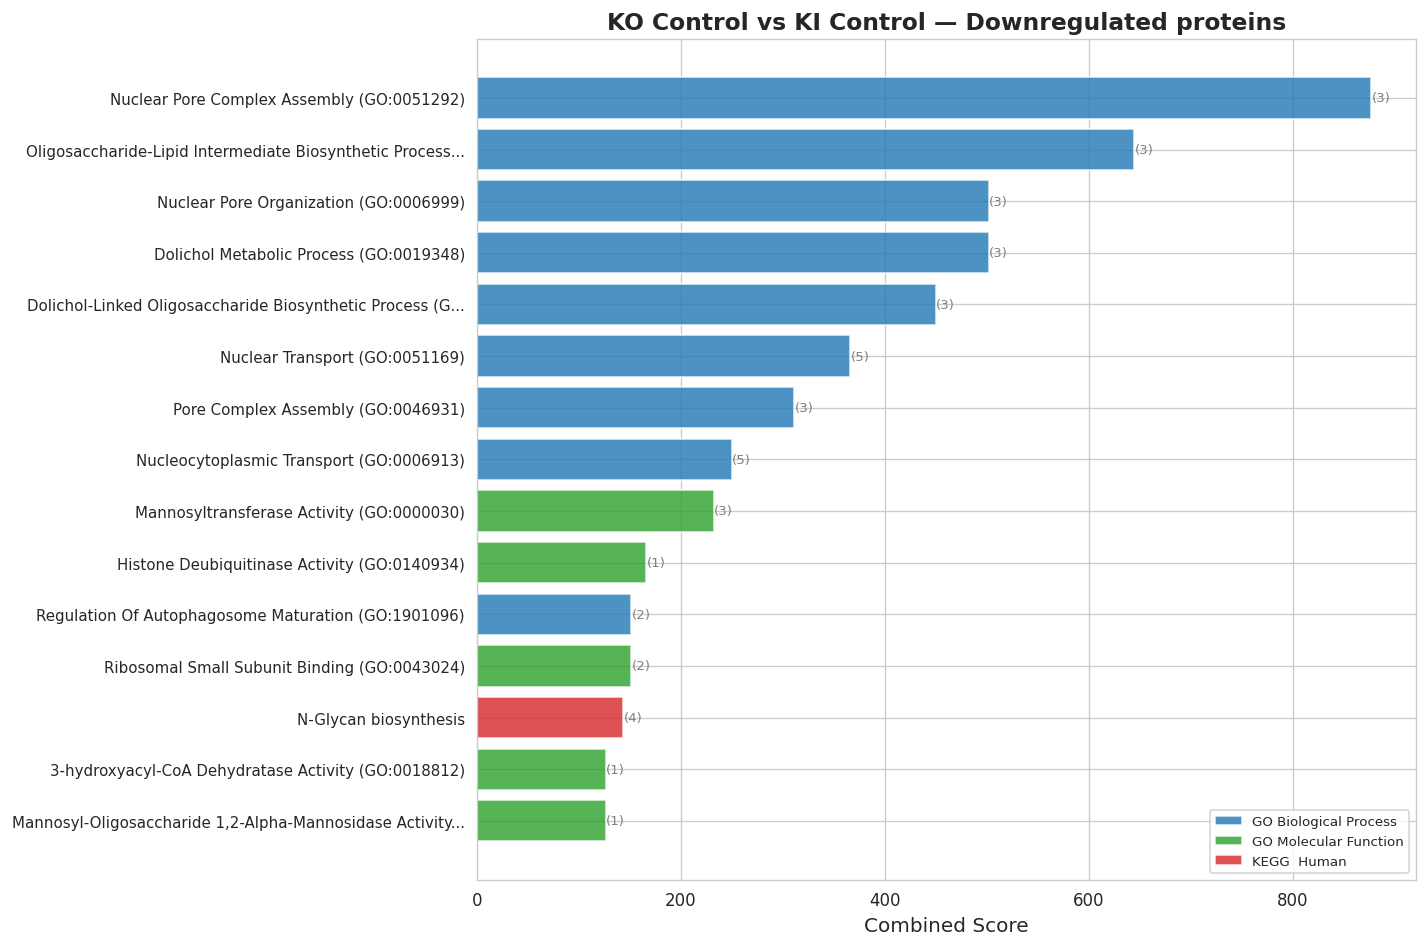

In [22]:
# ── KO Control vs KI Control enrichment ────────────────────────────────────────

if ctrl_results is not None and not ctrl_results.empty and 'Protein Gene' in ctrl_results.columns:
    ctrl_enrich_results = ptk.run_differential_enrichment(
        results_df=ctrl_results,
        gene_column='Protein Gene',
        logfc_column='logFC',
        pvalue_column='adj.P.Val',
        config=enrich_config,
    )

    if ctrl_enrich_results:
        for direction, enrich_df in ctrl_enrich_results.items():
            if not enrich_df.empty:
                print(f"\nControl comparison {direction} enrichment — top results:")
                print(enrich_df[['Term', 'Adj_P_Value', 'N_Genes']].head(10).to_string(index=False))
                ptk.plot_enrichment_barplot(
                    enrich_df,
                    title=f'KO Control vs KI Control — {direction} proteins',
                    top_n=15,
                )
                plt.savefig(f'figures/08b_enrichment_Ctrl_{direction}.png', dpi=150, bbox_inches='tight')
                plt.show()
else:
    print("No gene name column found in control comparison results — skipping enrichment")

Significant genes: 36 up, 8 down

Upregulated (36 genes):
Running enrichment on 36 genes...
  Found 28 significant terms

Downregulated (8 genes):
Running enrichment on 8 genes...
  Found 28 significant terms

Sex comparison Upregulated enrichment — top results:
                                                                  Term  Adj_P_Value  N_Genes
             Positive Regulation Of Immune System Process (GO:0002684) 1.031946e-07        5
                                   Complement and coagulation cascades 1.029281e-09        7
              Positive Regulation Of Response To Stimulus (GO:0048584) 7.174182e-06        5
                            Regulation Of Immune Response (GO:0050776) 7.174182e-06        5
                   Regulation Of Hepatocyte Proliferation (GO:2000345) 9.474090e-02        1
                Detection Of Molecule Of Bacterial Origin (GO:0032490) 9.474090e-02        1
                   Positive Regulation Of Immune Response (GO:0050778) 7.174182e-06   

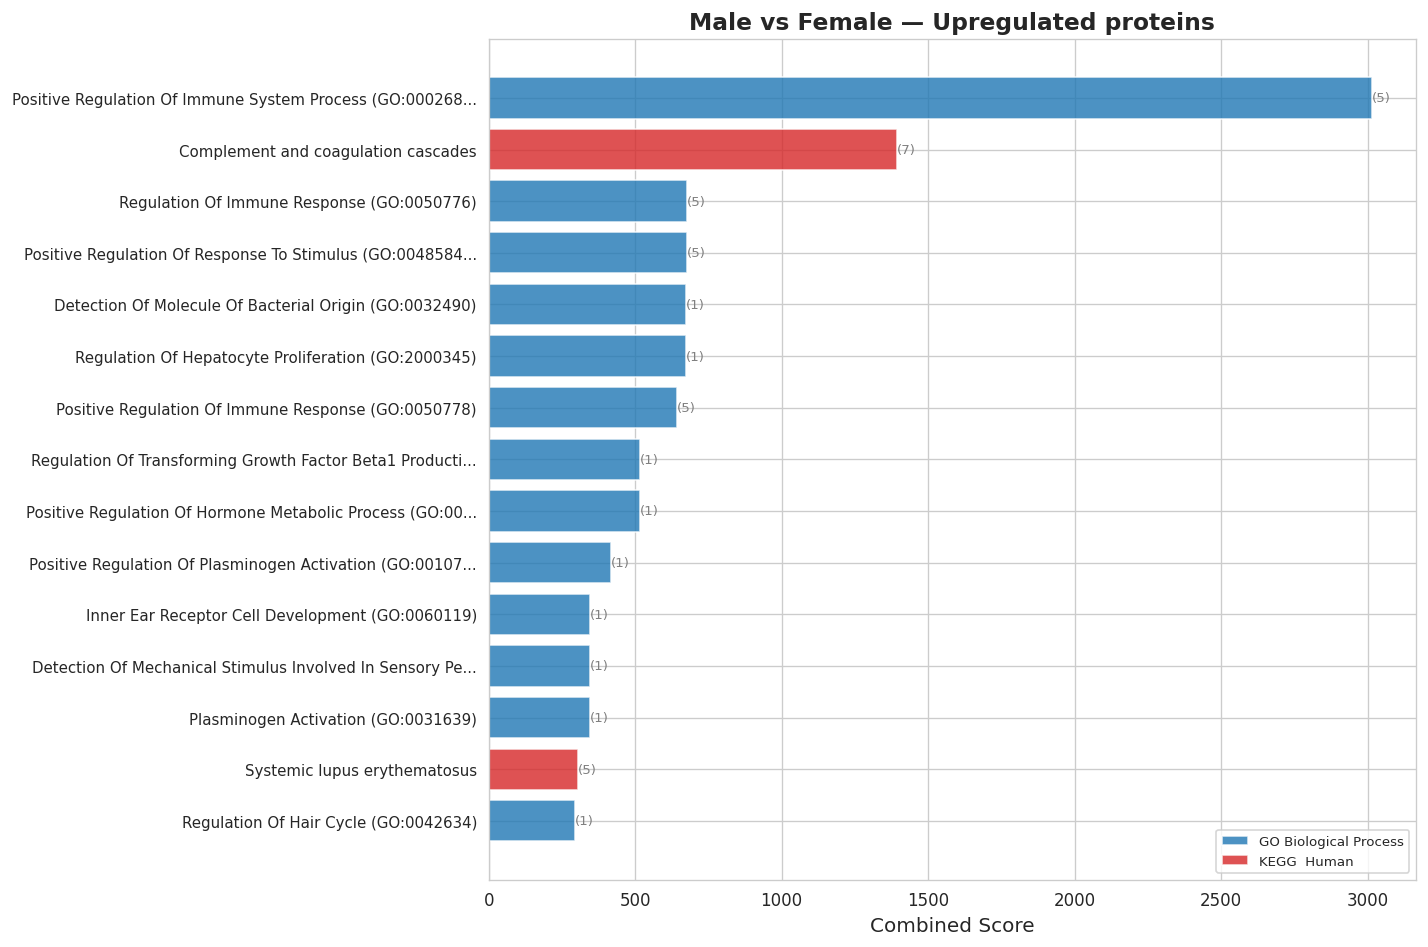


Sex comparison Downregulated enrichment — top results:
                                                                   Term  Adj_P_Value  N_Genes
                                  Chitin Catabolic Process (GO:0006032)     0.028979        1
                                  Chitin Metabolic Process (GO:0006030)     0.028979        1
                                        Chitinase Activity (GO:0004568)     0.013990        1
         Glucosamine-Containing Compound Catabolic Process (GO:1901072)     0.030895        1
                             Aminoglycan Catabolic Process (GO:0006026)     0.034714        1
                          Positive Regulation Of Secretion (GO:0051047)     0.034714        1
                                 Mammary Gland Development (GO:0030879)     0.042377        1
      Hydrolase Activity, Hydrolyzing O-glycosyl Compounds (GO:0004553)     0.040401        1
                               Response To Nutrient Levels (GO:0031667)     0.042650        1
Posi

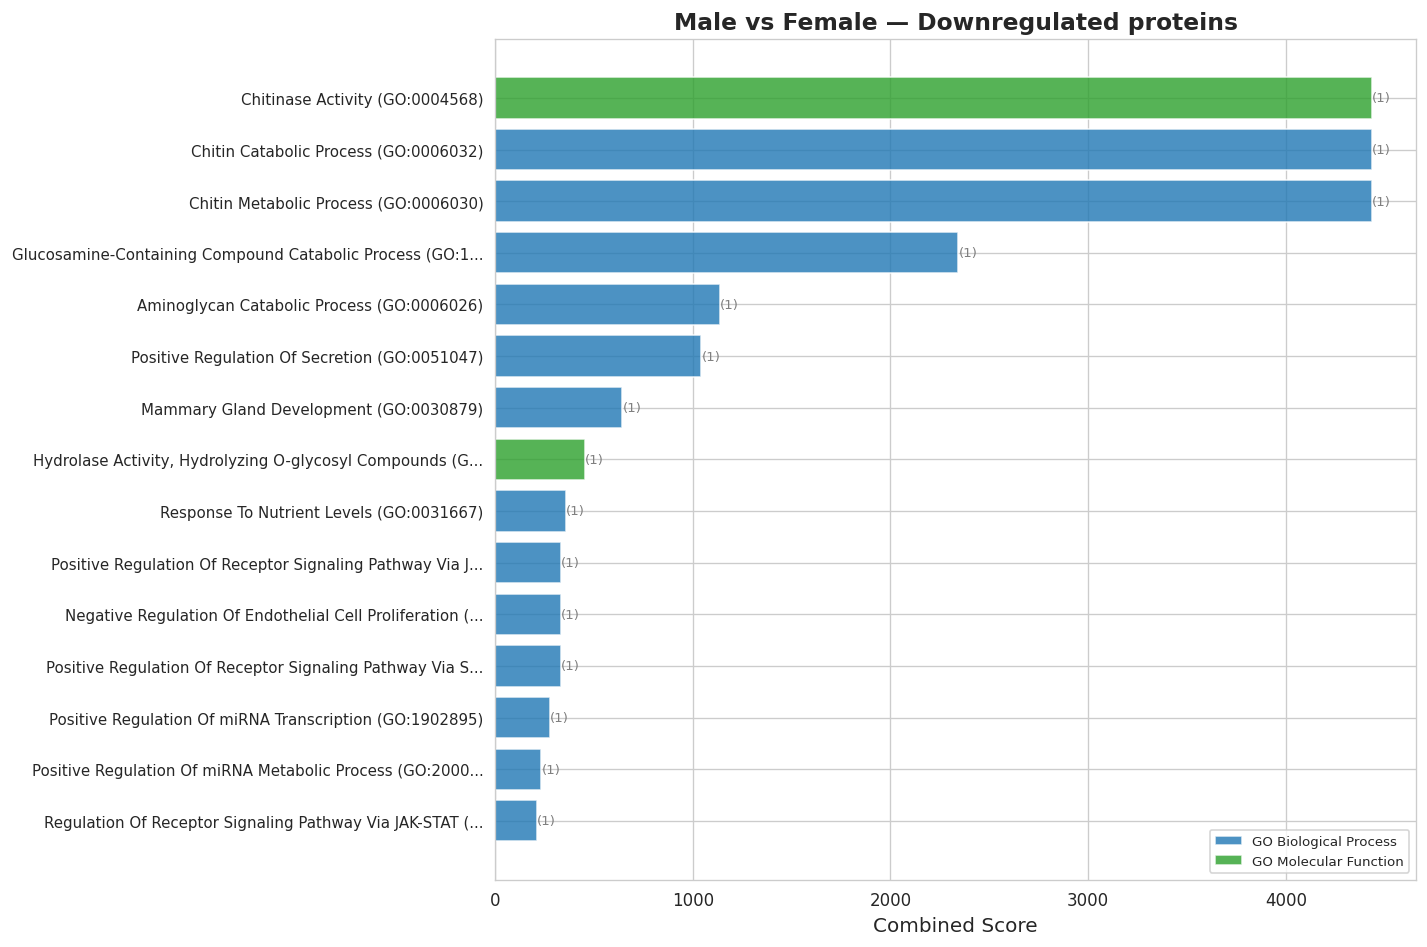

In [23]:
# ── Male vs Female enrichment ──────────────────────────────────────────────────

if sex_results is not None and not sex_results.empty and 'Protein Gene' in sex_results.columns:
    sex_enrich_results = ptk.run_differential_enrichment(
        results_df=sex_results,
        gene_column='Protein Gene',
        logfc_column='logFC',
        pvalue_column='adj.P.Val',
        config=enrich_config,
    )

    if sex_enrich_results:
        for direction, enrich_df in sex_enrich_results.items():
            if not enrich_df.empty:
                print(f"\nSex comparison {direction} enrichment — top results:")
                print(enrich_df[['Term', 'Adj_P_Value', 'N_Genes']].head(10).to_string(index=False))
                ptk.plot_enrichment_barplot(
                    enrich_df,
                    title=f'Male vs Female — {direction} proteins',
                    top_n=15,
                )
                plt.savefig(f'figures/08c_enrichment_Sex_{direction}.png', dpi=150, bbox_inches='tight')
                plt.show()
else:
    print("No gene name column found in sex comparison results — skipping enrichment")

---
## 7. MS Acquisition QC Metrics

In [24]:
import re

if os.path.exists(STATS_TSV):
    qc_stats = pd.read_csv(STATS_TSV, sep='\t')
    print(f"QC stats: {qc_stats.shape}")
    print(f"Columns: {list(qc_stats.columns)}")
    
    # Extract replicate name from file path column
    file_col = next((c for c in qc_stats.columns if 'file' in c.lower() or 'replicate' in c.lower()), None)
    if file_col:
        qc_stats['Replicate'] = qc_stats[file_col].apply(
            lambda x: re.search(r'([A-D]\d{1,2}-[^\\/.]+)', str(x)).group(1)
            if re.search(r'([A-D]\d{1,2}-[^\\/.]+)', str(x)) else str(x)
        )
        # Merge with metadata
        if metadata is not None:
            qc_merged = qc_stats.merge(
                metadata[['Replicate', 'Group', 'Sex']],
                on='Replicate', how='left'
            )
            qc_merged['Group'] = qc_merged['Group'].fillna('Unknown')
        else:
            qc_merged = qc_stats.copy()
        
        print(f"\nMerged QC stats: {qc_merged.shape}")
        display(qc_merged.head())
    else:
        print("Could not find file/replicate column")
        display(qc_stats.head())
else:
    print(f"QC stats file not found: {STATS_TSV}")

QC stats: (48, 17)
Columns: ['File.Name', 'Precursors.Identified', 'Proteins.Identified', 'Total.Quantity', 'MS1.Signal', 'MS2.Signal', 'FWHM.Scans', 'FWHM.RT', 'Median.Mass.Acc.MS1', 'Median.Mass.Acc.MS1.Corrected', 'Median.Mass.Acc.MS2', 'Median.Mass.Acc.MS2.Corrected', 'Normalisation.Instability', 'Median.RT.Prediction.Acc', 'Average.Peptide.Length', 'Average.Peptide.Charge', 'Average.Missed.Tryptic.Cleavages']

Merged QC stats: (48, 20)


,File.Name,Precursors.Identified,Proteins.Identified,Total.Quantity,MS1.Signal,MS2.Signal,FWHM.Scans,FWHM.RT,Median.Mass.Acc.MS1,Median.Mass.Acc.MS1.Corrected,Median.Mass.Acc.MS2,Median.Mass.Acc.MS2.Corrected,Normalisation.Instability,Median.RT.Prediction.Acc,Average.Peptide.Length,Average.Peptide.Charge,Average.Missed.Tryptic.Cleavages,Replicate,Group,Sex
0,T:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...,112339,8284,4.643110e+10,2587796751762,540275823930,2.444,0.056,0.638847,0.495908,1.35741,0.907457,1.000000,0.014413,12.428,2.351,0.317,A1-DDY6-001,KO Control,F
1,T:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...,33396,3582,5.358040e+10,3798664368419,713726769905,2.425,0.056,0.591134,0.317139,1.41173,0.848540,0.819864,0.039731,12.225,2.341,0.304,A10-168-010,KI Control,F
2,T:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...,41860,4349,7.870360e+10,5302173975451,1080646423976,2.548,0.056,0.726230,0.323584,1.20872,0.821463,0.998087,0.031075,12.358,2.344,0.310,A11-121-011,KI,M
3,T:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...,45587,4701,4.842770e+10,3158290782438,608690295924,2.392,0.055,0.656551,0.332457,1.35411,0.853044,1.000000,0.036955,12.259,2.347,0.306,A12-DFS2-012,KO Control,M
4,T:\2025-5-Carroll-Mouse-EV\2025-05-Ast-Carroll...,55936,5342,7.562010e+10,4666226231163,940280477615,2.461,0.055,0.593345,0.438622,1.39373,0.878381,1.000000,0.020694,12.400,2.349,0.313,A2-DDZ1-002,KO,M


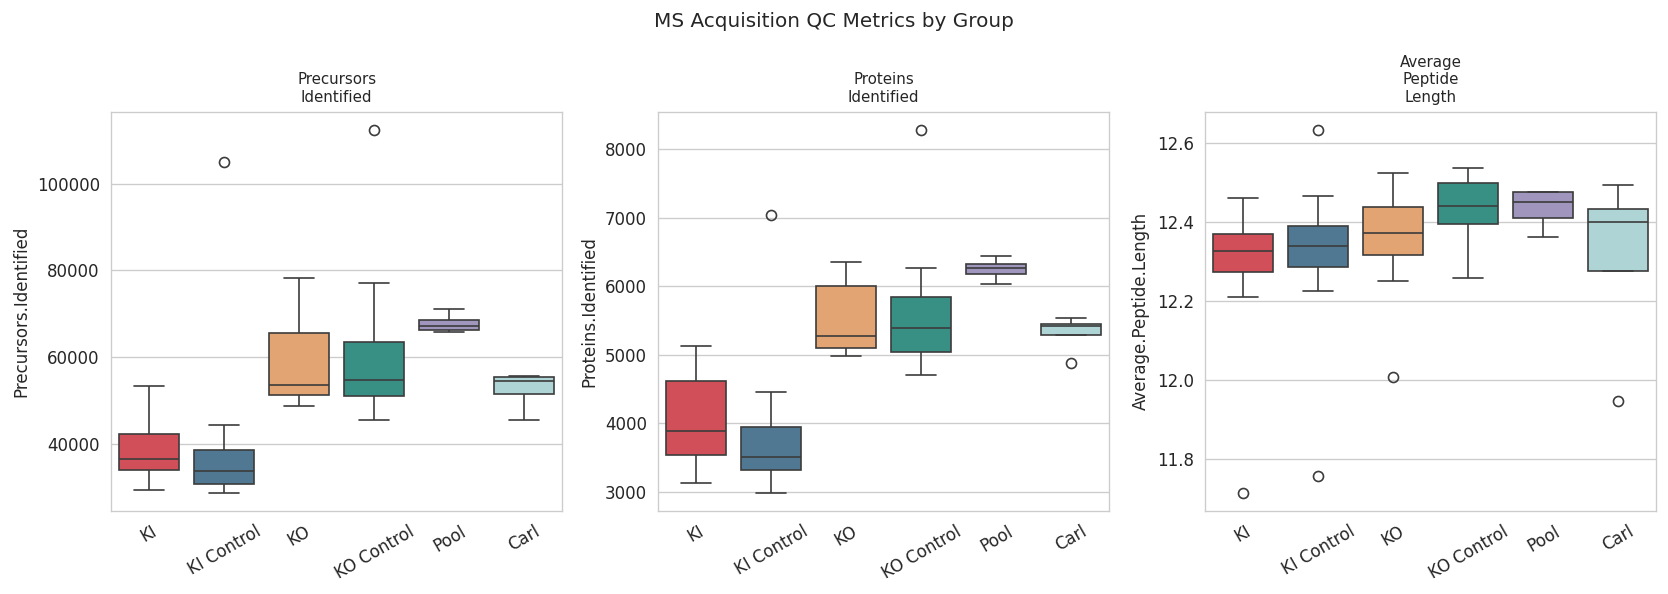

In [25]:
# Visualize key QC metrics across groups
if 'qc_merged' in dir() and not qc_merged.empty:
    # Find peptide/protein identification count columns
    id_cols = [c for c in qc_merged.columns if any(
        kw in c.lower() for kw in ['precursor', 'protein', 'peptide']
    ) and qc_merged[c].dtype in ['int64', 'float64']]

    if id_cols:
        fig, axes = plt.subplots(1, min(len(id_cols), 3), figsize=(14, 5))
        if len(id_cols) == 1:
            axes = [axes]
        
        for ax, col in zip(axes, id_cols[:3]):
            plot_df = qc_merged[['Group', col]].dropna()
            order = [g for g in GROUP_ORDER if g in plot_df['Group'].unique()]
            palette = {g: GROUP_COLORS.get(g, '#888888') for g in order}
            sns.boxplot(
                data=plot_df, x='Group', y=col, order=order,
                palette=palette, ax=ax
            )
            ax.set_title(col.replace('.', '\n'), fontsize=9)
            ax.set_xlabel('')
            ax.tick_params(axis='x', rotation=30)

        plt.suptitle('MS Acquisition QC Metrics by Group', fontsize=12)
        plt.tight_layout()
        plt.savefig('figures/09_qc_metrics.png', dpi=150, bbox_inches='tight')
        plt.show()
    else:
        print("No numeric identification count columns found")

---
## 8. Export Results

In [26]:
os.makedirs('results', exist_ok=True)

# Export all contrast results
for name, res in [
    ('KI_vs_KIControl', ki_results),
    ('KO_vs_KOControl', ko_results),
    ('KOControl_vs_KIControl', ctrl_results),
    ('Male_vs_Female', sex_results),
]:
    if res is not None and not res.empty:
        res.to_csv(f'results/{name}_stats.csv', index=False)
        n_sig = (res['adj.P.Val'] < 0.05).sum() if 'adj.P.Val' in res.columns else 0
        print(f"{name}: {len(res)} proteins, {n_sig} significant (FDR < 0.05)")

print("\nExport complete.")

KI_vs_KIControl: 8142 proteins, 0 significant (FDR < 0.05)
KO_vs_KOControl: 8142 proteins, 7 significant (FDR < 0.05)
KOControl_vs_KIControl: 8142 proteins, 298 significant (FDR < 0.05)
Male_vs_Female: 8142 proteins, 45 significant (FDR < 0.05)

Export complete.


---
## Session Info

In [27]:
import datetime
print(f"Analysis date: {datetime.date.today()}")
print(f"proteomics_toolkit: v{ptk.__version__}")
print(f"pandas: {pd.__version__}")
print(f"numpy: {np.__version__}")

import scipy, sklearn
print(f"scipy: {scipy.__version__}")
print(f"scikit-learn: {sklearn.__version__}")

Analysis date: 2026-03-09
proteomics_toolkit: v1.0.0
pandas: 3.0.1
numpy: 2.4.2
scipy: 1.17.1
scikit-learn: 1.8.0
